# Low-Light Image Enhancement
### DIP Project — Classical + Deep Learning Pipeline

**Dataset**: [LoL (Low-Light) Dataset](https://huggingface.co/datasets/geekyrakshit/LoL-Dataset) — 485 train + 15 test paired images.

In [1]:
from datasets import load_dataset
import numpy as np, cv2
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

from huggingface_hub import hf_hub_download
import zipfile, os

zp = hf_hub_download("geekyrakshit/LoL-Dataset", "lol_dataset.zip", repo_type="dataset")
zipfile.ZipFile(zp).extractall("lol")

# inspect the folder structure
for root, dirs, files in os.walk("lol"):
    print(root, len(files), "files", files[:2])

lol 0 files []
lol/lol_dataset 0 files []
lol/lol_dataset/eval15 1 files ['.DS_Store']
lol/lol_dataset/eval15/low 15 files ['547.png', '146.png']
lol/lol_dataset/eval15/high 15 files ['547.png', '146.png']
lol/lol_dataset/our485 0 files []
lol/lol_dataset/our485/low 486 files ['241.png', '546.png']
lol/lol_dataset/our485/high 486 files ['241.png', '546.png']


In [2]:
import glob, cv2, numpy as np, pandas as pd
from collections import defaultdict

# 1. Find low/high folders anywhere under lol/
pairs_dirs = defaultdict(dict)
for d in glob.glob("lol/**/", recursive=True):
    name = os.path.basename(d.rstrip("/")).lower()
    if name in ("low", "high"):
        pairs_dirs[os.path.dirname(d.rstrip("/"))][name] = d
print({k: list(v) for k, v in pairs_dirs.items()})

# 2. Match by filename, verify both images decode and shapes agree
rows = []
for parent, dd in pairs_dirs.items():
    if len(dd) < 2: continue
    split = os.path.basename(parent)
    lows = {os.path.basename(p): p for p in glob.glob(dd["low"] + "*")}
    highs = {os.path.basename(p): p for p in glob.glob(dd["high"] + "*")}
    for fn in sorted(set(lows) | set(highs)):
        r = dict(split=split, file=fn, low=lows.get(fn), high=highs.get(fn),
                 ok=False, reason="")
        if not (r["low"] and r["high"]):
            r["reason"] = "missing pair"
        else:
            a, b = cv2.imread(r["low"]), cv2.imread(r["high"])
            if a is None or b is None: r["reason"] = "corrupt/unreadable"
            elif a.shape != b.shape: r["reason"] = "shape mismatch"
            else:
                r.update(ok=True, h=a.shape[0], w=a.shape[1],
                         low_mean=a.mean(), high_mean=b.mean())
        rows.append(r)

df = pd.DataFrame(rows)

# 3. EDA summary
print(df.groupby("split").ok.agg(total="size", valid="sum"))
print("Dropped:\n", df[~df.ok][["split", "file", "reason"]])
good = df[df.ok].reset_index(drop=True)
print("Sizes:", good[["h", "w"]].value_counts().to_dict())
print("Mean brightness  low=%.1f  high=%.1f" % (good.low_mean.mean(), good.high_mean.mean()))
print(good[["low_mean", "high_mean"]].describe().round(1))

# 4. Clean path lists for all later steps
train = good[good.split.str.contains("485|train", case=False)]
test = good[good.split.str.contains("15|eval|test", case=False)]
print("train:", len(train), "test:", len(test))

{'lol/lol_dataset/eval15': ['low', 'high'], 'lol/lol_dataset/our485': ['low', 'high']}
        total  valid
split               
eval15     15     15
our485    485    485
Dropped:
 Empty DataFrame
Columns: [split, file, reason]
Index: []
Sizes: {(400, 600): 500}
Mean brightness  low=15.2  high=116.0
       low_mean  high_mean
count     500.0      500.0
mean       15.2      116.0
std        10.8       26.1
min         2.0       53.5
25%         8.6       97.6
50%        13.3      115.3
75%        18.9      135.7
max        83.6      192.0
train: 485 test: 15


## Classical Methods Baseline

In [3]:
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
import time

# 1. Loader: cv2 reads BGR, we keep BGR everywhere (metrics don't care, as long as it's consistent)
def load_pair(row):
    return cv2.imread(row.low), cv2.imread(row.high)

# 2. Evaluate any method(img_bgr) -> img_bgr on a split
def evaluate(method, df_split, save_dir=None):
    P, S, T = [], [], []
    for r in df_split.itertuples():
        low, gt = load_pair(r)
        t = time.time()
        out = method(low)
        T.append(time.time() - t)
        P.append(psnr(gt, out, data_range=255))
        S.append(ssim(gt, out, channel_axis=2, data_range=255))
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            cv2.imwrite(os.path.join(save_dir, r.file), out)
    return dict(PSNR=np.mean(P), SSIM=np.mean(S), ms_per_img=1000 * np.mean(T))

# 3. Methods
identity = lambda img: img

def clahe(img, clip=3.0, grid=8):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clip, (grid, grid)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

# 4. Run on test set
results = {name: evaluate(m, test) for name, m in
           [("Raw (no enhancement)", identity), ("CLAHE", clahe)]}
print(pd.DataFrame(results).T.round(3))

# 5. Quick CLAHE parameter sweep (on train, so test stays untouched)
sweep = []
for clip in [1, 2, 3, 4, 6]:
    for grid in [4, 8, 16]:
        r = evaluate(lambda x: clahe(x, clip, grid), train.sample(60, random_state=0))
        sweep.append(dict(clip=clip, grid=grid, **r))
sweep = pd.DataFrame(sweep).sort_values("PSNR", ascending=False)
print(sweep.head(5).round(3))

                       PSNR   SSIM  ms_per_img
Raw (no enhancement)  7.773  0.191       0.002
CLAHE                 9.655  0.400       9.230
    clip  grid    PSNR   SSIM  ms_per_img
12     6     4  11.006  0.487       4.945
13     6     8  10.388  0.459       5.090
14     6    16   9.951  0.436       5.182
9      4     4   9.935  0.448       5.113
10     4     8   9.546  0.424       5.013


In [4]:
from scipy.ndimage import gaussian_filter

def stretch(x, lo=1, hi=99):
    a, b = np.percentile(x, [lo, hi])
    return np.clip((x - a) / (b - a + 1e-6), 0, 1)

def gamma(img, g=0.4):
    return (255 * (img / 255.0) ** g).astype(np.uint8)

def retinex_log(ch, sigmas):
    ch = ch.astype(np.float64) + 1
    return sum(np.log(ch) - np.log(gaussian_filter(ch, s) + 1) for s in sigmas) / len(sigmas)

def msr(img, sigmas=(15, 80, 250), lo=1, hi=99):
    out = np.stack([stretch(retinex_log(img[..., c], sigmas), lo, hi) for c in range(3)], -1)
    return (out * 255).astype(np.uint8)

def msrcp(img, sigmas=(15, 80, 250), lo=1, hi=99):
    f = img.astype(np.float64) + 1
    I = f.sum(2) / 3
    I_out = stretch(retinex_log(I, sigmas), lo, hi) * 255 + 1
    A = np.minimum(256 / f.max(2), I_out / I)[..., None]
    return np.clip(A * f, 0, 255).astype(np.uint8)

ssr = lambda img, s=80, **k: msr(img, (s,), **k)

# Sweeps on train sample (test stays untouched)
S = train.sample(60, random_state=0)
def sweep(fn, grid):
    rows = [dict(params=p, **evaluate(lambda x: fn(x, **p), S)) for p in grid]
    return pd.DataFrame(rows).sort_values("PSNR", ascending=False).iloc[0]["params"]

best = {}
best["clahe"]  = sweep(clahe, [dict(clip=c, grid=g) for c in [6, 8, 12, 16] for g in [2, 4]])
best["gamma"]  = sweep(gamma, [dict(g=g) for g in [0.3, 0.4, 0.5, 0.6]])
best["ssr"]    = sweep(ssr,   [dict(s=s, lo=lo, hi=hi) for s in [15, 80, 250] for lo, hi in [(1, 99), (0.5, 90), (0, 80)]])
best["msr"]    = sweep(msr,   [dict(lo=lo, hi=hi) for lo, hi in [(1, 99), (0.5, 90), (0, 80)]])
best["msrcp"]  = sweep(msrcp, [dict(lo=lo, hi=hi) for lo, hi in [(1, 99), (0.5, 90), (0, 80)]])
print(best)

# Final comparison on test
methods = {
    "Raw": identity,
    "CLAHE": lambda x: clahe(x, **best["clahe"]),
    "Gamma": lambda x: gamma(x, **best["gamma"]),
    "SSR": lambda x: ssr(x, **best["ssr"]),
    "MSR": lambda x: msr(x, **best["msr"]),
    "MSRCP": lambda x: msrcp(x, **best["msrcp"]),
}
final = pd.DataFrame({n: evaluate(m, test, save_dir=f"out/{n}") for n, m in methods.items()}).T
print(final.round(3))

{'clahe': {'clip': 16, 'grid': 2}, 'gamma': {'g': 0.3}, 'ssr': {'s': 250, 'lo': 1, 'hi': 99}, 'msr': {'lo': 1, 'hi': 99}, 'msrcp': {'lo': 1, 'hi': 99}}
         PSNR   SSIM  ms_per_img
Raw     7.773  0.191       0.003
CLAHE  14.925  0.455       4.897
Gamma  16.641  0.641      12.588
SSR    13.842  0.513    2082.011
MSR    12.792  0.479    2831.212
MSRCP  13.703  0.385     967.112


In [5]:
def gamma_clahe(img, g=0.5, clip=3, grid=8):
    return clahe(gamma(img, g), clip, grid)

S = train.sample(60, random_state=0)
best["gamma"] = sweep(gamma, [dict(g=g) for g in [0.15, 0.2, 0.25, 0.3, 0.35]])
best["clahe"] = sweep(clahe, [dict(clip=c, grid=g) for c in [16, 24, 32, 40] for g in [1, 2]])
best["gc"]    = sweep(gamma_clahe, [dict(g=g, clip=c, grid=gr)
                      for g in [0.3, 0.4, 0.5] for c in [1, 2, 3] for gr in [4, 8]])
print(best)

new = {
    "Gamma": lambda x: gamma(x, **best["gamma"]),
    "CLAHE": lambda x: clahe(x, **best["clahe"]),
    "Gamma+CLAHE": lambda x: gamma_clahe(x, **best["gc"]),
}
upd = pd.DataFrame({n: evaluate(m, test, save_dir=f"out/{n}") for n, m in new.items()}).T
final = pd.concat([final.drop(index=list(new), errors="ignore"), upd])
print(final.round(3))

{'clahe': {'clip': 24, 'grid': 1}, 'gamma': {'g': 0.25}, 'ssr': {'s': 250, 'lo': 1, 'hi': 99}, 'msr': {'lo': 1, 'hi': 99}, 'msrcp': {'lo': 1, 'hi': 99}, 'gc': {'g': 0.3, 'clip': 1, 'grid': 4}}
               PSNR   SSIM  ms_per_img
Raw           7.773  0.191       0.003
SSR          13.842  0.513    2082.011
MSR          12.792  0.479    2831.212
MSRCP        13.703  0.385     967.112
Gamma        16.884  0.635      12.577
CLAHE        15.473  0.461       5.152
Gamma+CLAHE  17.413  0.634      18.655


In [6]:
def enhance_dn(img, g=0.3, h=5, clip=1, grid=4, order="gamma_dn_clahe"):
    x = gamma(img, g)
    if h > 0:
        x = cv2.fastNlMeansDenoisingColored(x, None, h, h, 5, 15)
    return clahe(x, clip, grid) if clip > 0 else x

S = train.sample(30, random_state=0)  # NLM is slower, smaller sample
best["dn"] = sweep(enhance_dn, [dict(g=g, h=h, clip=c, grid=4)
                 for g in [0.25, 0.3, 0.35] for h in [3, 7, 12] for c in [0, 1]])
print(best["dn"])

final.loc["Gamma+DN+CLAHE"] = evaluate(lambda x: enhance_dn(x, **best["dn"]), test, save_dir="out/Gamma+DN+CLAHE")
print(final.round(3))

{'g': 0.25, 'h': 7, 'clip': 1, 'grid': 4}
                  PSNR   SSIM  ms_per_img
Raw              7.773  0.191       0.003
SSR             13.842  0.513    2082.011
MSR             12.792  0.479    2831.212
MSRCP           13.703  0.385     967.112
Gamma           16.884  0.635      12.577
CLAHE           15.473  0.461       5.152
Gamma+CLAHE     17.413  0.634      18.655
Gamma+DN+CLAHE  17.312  0.664     409.642


## Deep Learning: Improved U-Net

**Key improvements over the original notebook:**
1. **4-level encoder** (3 pooling stages) for larger receptive field
2. **InstanceNorm + LeakyReLU** for stable training
3. **Combined loss**: L1 + SSIM + VGG perceptual
4. **Per-image random crops** (not shared across batch)
5. **Full augmentation**: horizontal flip, vertical flip, 90° rotation
6. **Cosine LR schedule** with warmup decay
7. **Gradient clipping** for stability
8. **Validation loop** with best-model checkpointing

In [7]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvmodels
from torch.optim.lr_scheduler import CosineAnnealingLR

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)

# ─── Prepare data (gamma-brightened input → ground truth) ───
def prep(df_):
    X, Y = [], []
    for r in df_.itertuples():
        lo, gt = load_pair(r)
        X.append(gamma(lo, 0.3)); Y.append(gt)
    return np.stack(X), np.stack(Y)

Xtr, Ytr = prep(train)
Xte, Yte = prep(test)
print(f"Train: {Xtr.shape}  Test: {Xte.shape}")

# ─── Improved U-Net: 4 encoder levels, InstanceNorm, LeakyReLU ───
def conv_block(inc, outc):
    return nn.Sequential(
        nn.Conv2d(inc, outc, 3, padding=1), nn.InstanceNorm2d(outc), nn.LeakyReLU(0.2, True),
        nn.Conv2d(outc, outc, 3, padding=1), nn.InstanceNorm2d(outc), nn.LeakyReLU(0.2, True),
    )

class UNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        c1, c2, c3, c4 = base, base*2, base*4, base*8
        # Encoder
        self.e1 = conv_block(3, c1)
        self.e2 = conv_block(c1, c2)
        self.e3 = conv_block(c2, c3)
        # Bottleneck
        self.b  = conv_block(c3, c4)
        # Decoder
        self.u3 = nn.ConvTranspose2d(c4, c3, 2, 2)
        self.d3 = conv_block(c3 * 2, c3)
        self.u2 = nn.ConvTranspose2d(c3, c2, 2, 2)
        self.d2 = conv_block(c2 * 2, c2)
        self.u1 = nn.ConvTranspose2d(c2, c1, 2, 2)
        self.d1 = conv_block(c1 * 2, c1)
        self.out = nn.Conv2d(c1, 3, 1)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(F.max_pool2d(e1, 2))
        e3 = self.e3(F.max_pool2d(e2, 2))
        b  = self.b(F.max_pool2d(e3, 2))
        d3 = self.d3(torch.cat([self.u3(b), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return (x + self.out(d1)).clamp(0, 1)  # residual learning

net = UNet(base=32).to(dev)
nparams = sum(p.numel() for p in net.parameters())
print(f"Model parameters: {nparams:,}")

# ─── Loss functions ───
class SSIMLoss(nn.Module):
    """Differentiable 1-SSIM loss."""
    def __init__(self, win=11, c1=0.01**2, c2=0.03**2):
        super().__init__()
        self.c1, self.c2, self.win = c1, c2, win
        self.register_buffer('kernel', torch.ones(1, 1, win, win) / win**2)

    def forward(self, x, y):
        C = x.shape[1]
        k = self.kernel.expand(C, -1, -1, -1)
        p = self.win // 2
        mu_x  = F.conv2d(x, k, padding=p, groups=C)
        mu_y  = F.conv2d(y, k, padding=p, groups=C)
        sig_x  = F.conv2d(x * x, k, padding=p, groups=C) - mu_x ** 2
        sig_y  = F.conv2d(y * y, k, padding=p, groups=C) - mu_y ** 2
        sig_xy = F.conv2d(x * y, k, padding=p, groups=C) - mu_x * mu_y
        ssim_map = ((2 * mu_x * mu_y + self.c1) * (2 * sig_xy + self.c2)) / \
                   ((mu_x**2 + mu_y**2 + self.c1) * (sig_x + sig_y + self.c2))
        return 1 - ssim_map.mean()

class VGGLoss(nn.Module):
    """Perceptual loss using VGG16 conv3_3 features."""
    def __init__(self):
        super().__init__()
        vgg = tvmodels.vgg16(weights='IMAGENET1K_V1').features[:16].eval()
        for p in vgg.parameters():
            p.requires_grad = False
        self.vgg = vgg
        self.register_buffer('mean', torch.tensor([.485, .456, .406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([.229, .224, .225]).view(1, 3, 1, 1))

    def forward(self, x, y):
        x = (x - self.mean) / self.std
        y = (y - self.mean) / self.std
        return F.l1_loss(self.vgg(x), self.vgg(y))

ssim_loss_fn = SSIMLoss().to(dev)
try:
    vgg_loss_fn = VGGLoss().to(dev)
    use_vgg = True
    print("VGG perceptual loss: enabled")
except Exception as e:
    use_vgg = False
    print(f"VGG perceptual loss: disabled ({e})")

print("\nReady to train!")

Device: cuda
Train: (485, 400, 600, 3)  Test: (15, 400, 600, 3)
Model parameters: 1,925,667
VGG perceptual loss: enabled

Ready to train!


In [9]:
# ─────────────────────────────────────────────
# Training configuration
# ─────────────────────────────────────────────

STEPS = 50_000
BS = 8
CS = 192

# Disable VGG initially to check training speed
use_vgg = False

print("Device:", dev)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ─────────────────────────────────────────────
# Optimizer + Scheduler
# ─────────────────────────────────────────────

opt = torch.optim.AdamW(
    net.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

sched = torch.optim.lr_scheduler.CosineAnnealingLR(
    opt,
    T_max=STEPS,
    eta_min=1e-6
)

# ─────────────────────────────────────────────
# Conversion function
# ─────────────────────────────────────────────

def to_t(a):
    return (
        torch.from_numpy(a)
        .permute(0, 3, 1, 2)
        .float()
        .div(255)
        .to(dev)
    )

# ─────────────────────────────────────────────
# Initial values
# ─────────────────────────────────────────────

best_val_psnr = 0.0

H, W = Xtr.shape[1], Xtr.shape[2]

log = []

print("\nStarting training...")
print(f"Training images : {len(Xtr)}")
print(f"Validation images: {len(Xte)}")
print(f"Image size      : {H} x {W}")
print(f"Crop size       : {CS}")
print(f"Batch size      : {BS}")
print(f"Total steps     : {STEPS}")
print(f"VGG loss        : {use_vgg}")
print("-" * 60)

# ─────────────────────────────────────────────
# Training loop
# ─────────────────────────────────────────────

for step in range(1, STEPS + 1):

    net.train()

    # Random images
    idx = np.random.randint(
        0,
        len(Xtr),
        BS
    )

    cx = []
    cy = []

    # ─────────────────────────────────────────
    # Random crop for every image
    # ─────────────────────────────────────────

    for i in idx:

        y0 = np.random.randint(
            0,
            H - CS + 1
        )

        x0 = np.random.randint(
            0,
            W - CS + 1
        )

        cx.append(
            Xtr[
                i,
                y0:y0 + CS,
                x0:x0 + CS
            ]
        )

        cy.append(
            Ytr[
                i,
                y0:y0 + CS,
                x0:x0 + CS
            ]
        )

    xb = to_t(np.stack(cx))
    yb = to_t(np.stack(cy))

    # ─────────────────────────────────────────
    # Data augmentation
    # ─────────────────────────────────────────

    # Horizontal flip
    if np.random.rand() < 0.5:

        xb = xb.flip(3)
        yb = yb.flip(3)

    # Vertical flip
    if np.random.rand() < 0.5:

        xb = xb.flip(2)
        yb = yb.flip(2)

    # 90 degree rotation
    if np.random.rand() < 0.3:

        xb = xb.transpose(2, 3)
        yb = yb.transpose(2, 3)

    # ─────────────────────────────────────────
    # Forward pass
    # ─────────────────────────────────────────

    pred = net(xb)

    # ─────────────────────────────────────────
    # Loss
    # ─────────────────────────────────────────

    loss = (
        F.l1_loss(pred, yb)
        + 0.2 * ssim_loss_fn(pred, yb)
    )

    if use_vgg:

        loss = (
            loss
            + 0.1 * vgg_loss_fn(pred, yb)
        )

    # ─────────────────────────────────────────
    # Backpropagation
    # ─────────────────────────────────────────

    opt.zero_grad(set_to_none=True)

    loss.backward()

    nn.utils.clip_grad_norm_(
        net.parameters(),
        1.0
    )

    opt.step()

    sched.step()

    # ─────────────────────────────────────────
    # Simple progress check
    # ─────────────────────────────────────────

    if step % 100 == 0:

        print(
            f"Training step: {step}/{STEPS}",
            flush=True
        )

    # ─────────────────────────────────────────
    # Validation
    # ─────────────────────────────────────────

    if step % 500 == 0 or step == 1:

        net.eval()

        with torch.no_grad():

            vpsnrs = []
            vssims = []

            for j in range(len(Xte)):

                # Convert test image
                xv = to_t(
                    Xte[j:j + 1]
                )

                h = xv.shape[2]
                w = xv.shape[3]

                # Pad to multiple of 8
                ph = (-h) % 8
                pw = (-w) % 8

                if ph or pw:

                    xv = F.pad(
                        xv,
                        (0, pw, 0, ph),
                        mode="reflect"
                    )

                # Prediction
                pv = net(xv)

                # Remove padding
                pv = pv[
                    :,
                    :,
                    :h,
                    :w
                ]

                # Convert to uint8
                pv_np = (
                    pv[0]
                    .permute(1, 2, 0)
                    .cpu()
                    .numpy()
                    * 255
                ).clip(
                    0,
                    255
                ).astype(
                    np.uint8
                )

                gt_np = Yte[j]

                # PSNR
                vpsnrs.append(
                    psnr(
                        gt_np,
                        pv_np,
                        data_range=255
                    )
                )

                # SSIM
                vssims.append(
                    ssim(
                        gt_np,
                        pv_np,
                        channel_axis=2,
                        data_range=255
                    )
                )

            mpsnr = np.mean(vpsnrs)
            mssim = np.mean(vssims)

        # Current learning rate
        lr = opt.param_groups[0]["lr"]

        tag = ""

        # ─────────────────────────────────────
        # Save best model
        # ─────────────────────────────────────

        if mpsnr > best_val_psnr:

            best_val_psnr = mpsnr

            torch.save(
                net.state_dict(),
                "unet_lowlight_best.pth"
            )

            tag = " ★ saved"

        # ─────────────────────────────────────
        # Print validation result
        # ─────────────────────────────────────

        print(
            f"\n[{step:6d}/{STEPS}] "
            f"loss={loss.item():.4f}  "
            f"PSNR={mpsnr:.2f}  "
            f"SSIM={mssim:.3f}  "
            f"lr={lr:.1e}"
            f"{tag}",
            flush=True
        )

        log.append(
            {
                "step": step,
                "loss": loss.item(),
                "psnr": mpsnr,
                "ssim": mssim,
                "lr": lr
            }
        )

# ─────────────────────────────────────────────
# Load best model
# ─────────────────────────────────────────────

net.load_state_dict(
    torch.load(
        "unet_lowlight_best.pth",
        map_location=dev
    )
)

net.eval()

print("\n" + "=" * 60)
print("Training complete!")
print(f"Best validation PSNR: {best_val_psnr:.2f} dB")
print("=" * 60)

  

Device: cuda
CUDA available: True
GPU: Tesla T4

Starting training...
Training images : 485
Validation images: 15
Image size      : 400 x 600
Crop size       : 192
Batch size      : 8
Total steps     : 50000
VGG loss        : False
------------------------------------------------------------

[     1/50000] loss=0.1401  PSNR=19.76  SSIM=0.758  lr=2.0e-04 ★ saved
Training step: 100/50000
Training step: 200/50000
Training step: 300/50000
Training step: 400/50000
Training step: 500/50000

[   500/50000] loss=0.1819  PSNR=19.80  SSIM=0.768  lr=2.0e-04 ★ saved
Training step: 600/50000
Training step: 700/50000
Training step: 800/50000
Training step: 900/50000
Training step: 1000/50000

[  1000/50000] loss=0.1289  PSNR=19.69  SSIM=0.769  lr=2.0e-04
Training step: 1100/50000
Training step: 1200/50000
Training step: 1300/50000
Training step: 1400/50000
Training step: 1500/50000

[  1500/50000] loss=0.1084  PSNR=20.18  SSIM=0.775  lr=2.0e-04 ★ saved
Training step: 1600/50000
Training step: 1700/

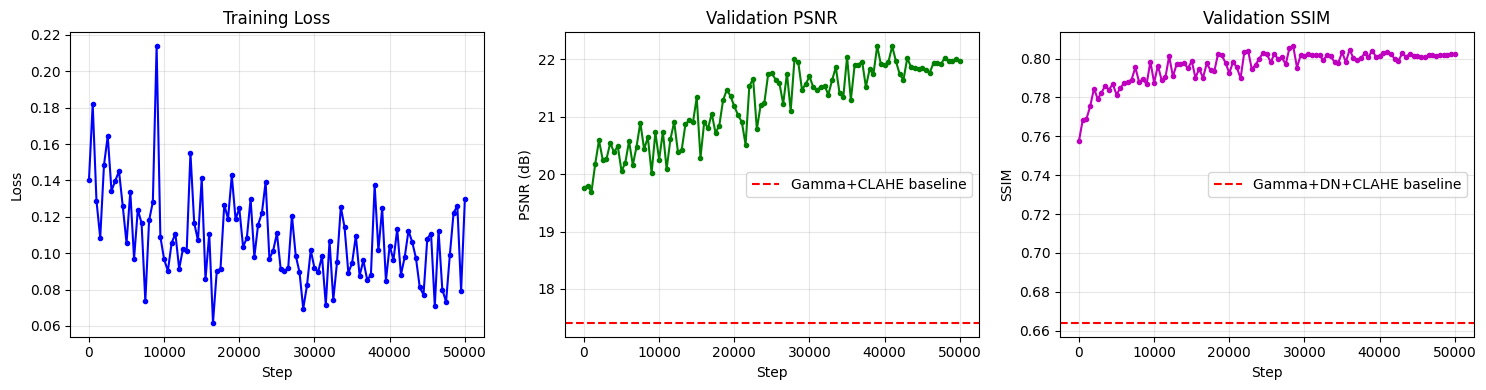

In [10]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))
log_df = pd.DataFrame(log)

ax1.plot(log_df.step, log_df.loss, 'b-o', markersize=3)
ax1.set_xlabel("Step"); ax1.set_ylabel("Loss"); ax1.set_title("Training Loss")
ax1.grid(True, alpha=0.3)

ax2.plot(log_df.step, log_df.psnr, 'g-o', markersize=3)
ax2.axhline(y=17.41, color='r', linestyle='--', label='Gamma+CLAHE baseline')
ax2.set_xlabel("Step"); ax2.set_ylabel("PSNR (dB)"); ax2.set_title("Validation PSNR")
ax2.legend(); ax2.grid(True, alpha=0.3)

ax3.plot(log_df.step, log_df.ssim, 'm-o', markersize=3)
ax3.axhline(y=0.664, color='r', linestyle='--', label='Gamma+DN+CLAHE baseline')
ax3.set_xlabel("Step"); ax3.set_ylabel("SSIM"); ax3.set_title("Validation SSIM")
ax3.legend(); ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Plug improved CNN into the same evaluate() framework
@torch.no_grad()
def cnn_enhanced(img):
    """Inference: gamma-brighten then U-Net residual correction."""
    net.eval()
    inp = gamma(img, 0.3)
    h, w = inp.shape[:2]
    x = torch.from_numpy(inp).permute(2, 0, 1)[None].float().div(255).to(dev)
    # Pad to multiple of 8 for 3-level pooling
    ph, pw = (-h) % 8, (-w) % 8
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode='reflect')
    out = net(x)[0, :, :h, :w].permute(1, 2, 0).cpu().numpy()
    return (out * 255).clip(0, 255).astype(np.uint8)

final.loc["CNN (U-Net v2)"] = evaluate(cnn_enhanced, test, save_dir="out/CNN_v2")

# ─── Final comparison table ───
print("=" * 55)
print("       FINAL RESULTS — All Methods Compared")
print("=" * 55)
print(final.sort_values("PSNR", ascending=False).round(3))
print()

# Save weights for deployment
import shutil
shutil.copy("unet_lowlight_best.pth", "unet_lowlight.pth")
print("Saved model as unet_lowlight.pth for app.py deployment")

       FINAL RESULTS — All Methods Compared
                  PSNR   SSIM  ms_per_img
CNN (U-Net v2)  22.227  0.804      41.806
Gamma+CLAHE     17.413  0.634      18.655
Gamma+DN+CLAHE  17.312  0.664     409.642
Gamma           16.884  0.635      12.577
CLAHE           15.473  0.461       5.152
SSR             13.842  0.513    2082.011
MSRCP           13.703  0.385     967.112
MSR             12.792  0.479    2831.212
Raw              7.773  0.191       0.003

Saved model as unet_lowlight.pth for app.py deployment


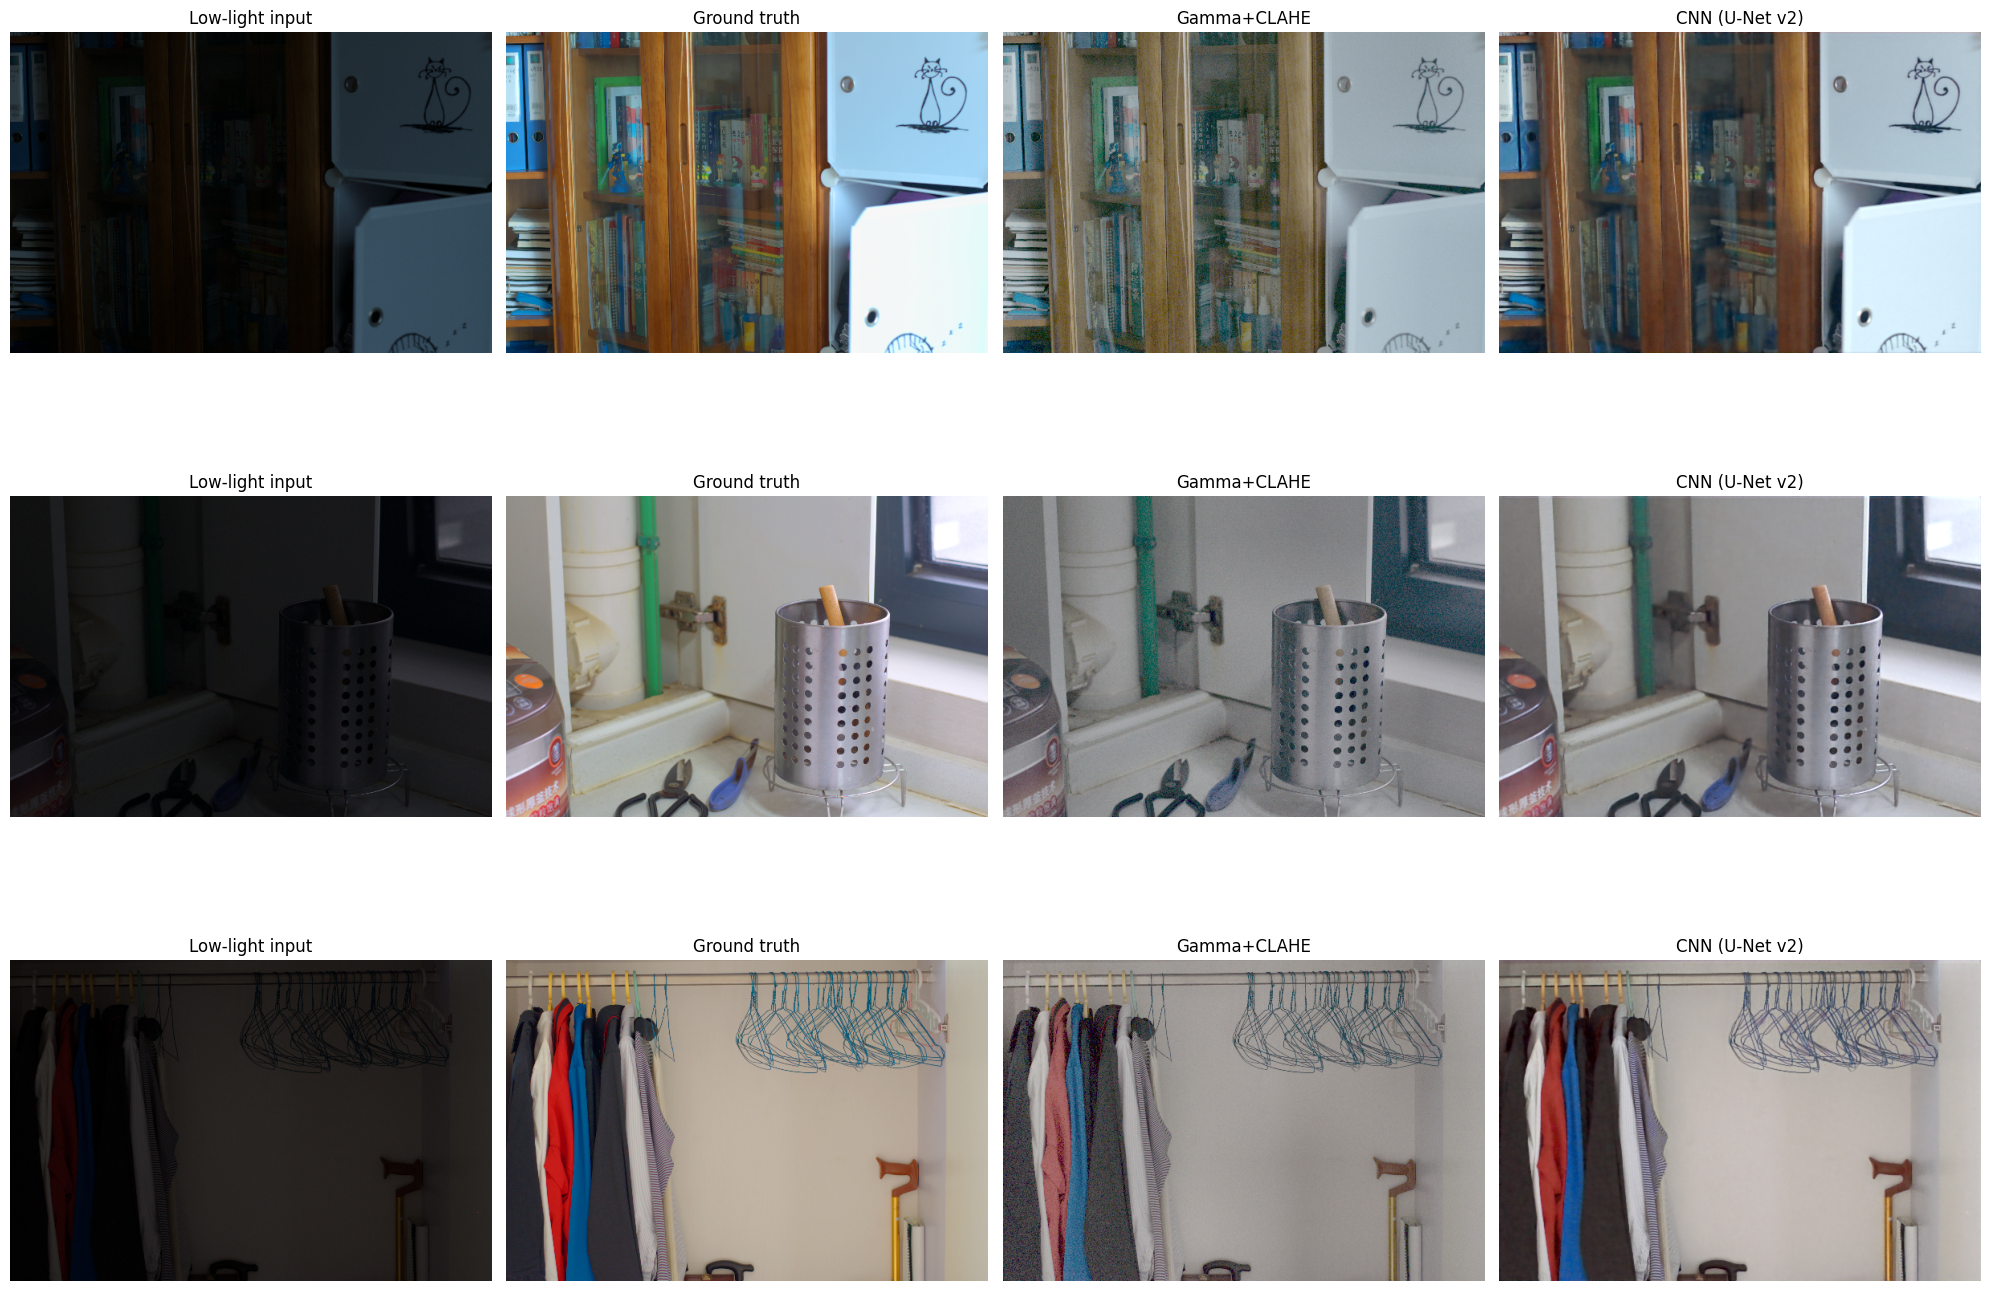

In [12]:
import matplotlib.pyplot as plt

# Show a side-by-side comparison on 3 test images
n_show = min(3, len(Xte))
fig, axes = plt.subplots(n_show, 4, figsize=(20, 5 * n_show))
if n_show == 1: axes = axes[None]

for i in range(n_show):
    lo_raw = cv2.imread(test.iloc[i].low)
    gt = cv2.imread(test.iloc[i].high)
    gc_out = gamma_clahe(lo_raw, **best["gc"])
    cnn_out = cnn_enhanced(lo_raw)

    for ax, img, title in zip(axes[i], [lo_raw, gt, gc_out, cnn_out],
                               ["Low-light input", "Ground truth", "Gamma+CLAHE", "CNN (U-Net v2)"]):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=12)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import shutil
shutil.make_archive("/kaggle/working/out_images", "zip", "/kaggle/working", "out")